# 05 — Model Evaluation & Important Factors

## Objective
Evaluate the saved Random Forest model on the held-out test set.

### Evaluation metrics
- Confusion Matrix
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC

### Why PR-AUC?
Failure prediction is a classification problem where false alarms and missed failures both matter. Precision-Recall analysis is especially informative when the failure class is less common.

> The model's "important factors" below are **global model importance**, not proof of causation and not a guarantee that those factors caused an individual failure.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    average_precision_score, roc_curve, precision_recall_curve
)
from sklearn.inspection import permutation_importance

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

X_test = pd.read_csv(PROCESSED_DIR / "X_test.csv")
y_test = pd.read_csv(PROCESSED_DIR / "y_test.csv").squeeze("columns")

preprocessor = joblib.load(MODEL_DIR / "preprocessor.pkl")
model = joblib.load(MODEL_DIR / "random_forest_model.pkl")

X_test_p = preprocessor.transform(X_test)
probability = model.predict_proba(X_test_p)[:, 1]
prediction = (probability >= 0.50).astype(int)

In [2]:
# Classification report
print(classification_report(
    y_test,
    prediction,
    target_names=["Normal", "Failure"],
    digits=3
))

print("ROC-AUC:", round(roc_auc_score(y_test, probability), 4))
print("PR-AUC :", round(average_precision_score(y_test, probability), 4))

              precision    recall  f1-score   support

      Normal      0.977     0.951     0.964      2087
     Failure      0.723     0.850     0.781       313

    accuracy                          0.938      2400
   macro avg      0.850     0.900     0.873      2400
weighted avg      0.944     0.938     0.940      2400

ROC-AUC: 0.9762
PR-AUC : 0.8688


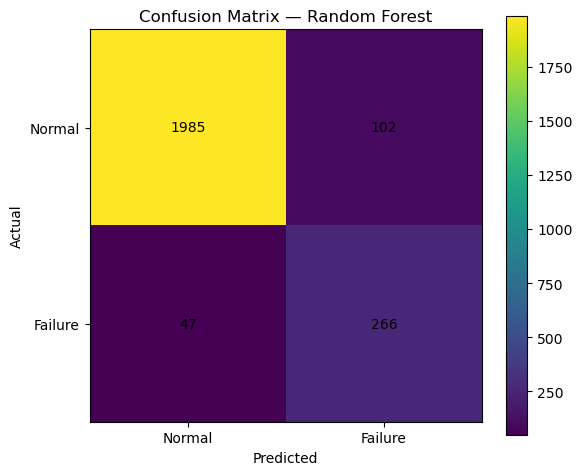

In [3]:
# Confusion matrix
cm = confusion_matrix(y_test, prediction)

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest")
plt.colorbar()
plt.xticks([0, 1], ["Normal", "Failure"])
plt.yticks([0, 1], ["Normal", "Failure"])
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")
plt.title("Confusion Matrix — Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_confusion_matrix.png", dpi=150)
plt.show()

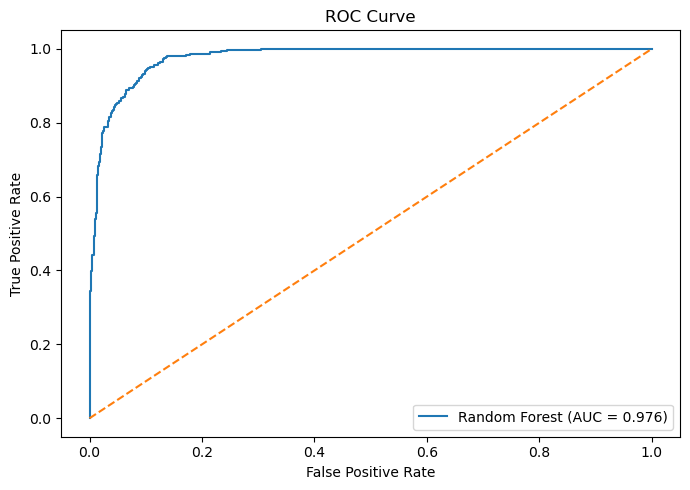

In [4]:
# ROC curve
fpr, tpr, _ = roc_curve(y_test, probability)
roc_auc = roc_auc_score(y_test, probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "07_roc_curve.png", dpi=150)
plt.show()

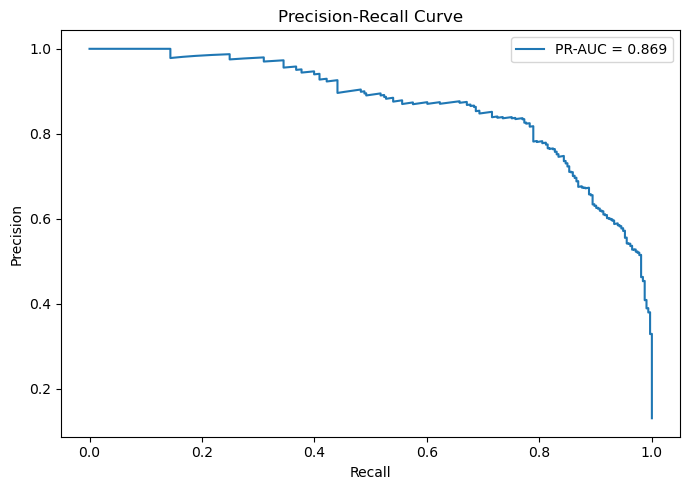

In [5]:
# Precision-Recall curve
precision, recall, _ = precision_recall_curve(y_test, probability)
pr_auc = average_precision_score(y_test, probability)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "08_precision_recall_curve.png", dpi=150)
plt.show()

In [6]:
# Global permutation importance on the ORIGINAL input columns.
# This avoids reporting separate one-hot importance for L/M/H as if they were separate physical factors.
result = permutation_importance(
    model,
    X_test_p,
    y_test,
    n_repeats=5,
    random_state=42,
    scoring="average_precision",
    n_jobs=1
)

feature_names = preprocessor.get_feature_names_out()
importance_df = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Importance_Mean": result.importances_mean,
    "Importance_Std": result.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df.head(15))

,Encoded_Feature,Importance_Mean,Importance_Std
6,num__Operating_Hours,0.722636,0.011464
7,num__Tool_Wear_Min,0.050658,0.006041
2,num__Vibration_mm_s,0.031658,0.004349
0,num__Temperature_C,0.008385,0.005056
3,num__Rotational_Speed_rpm,0.005294,0.002937
1,num__Pressure_bar,0.002981,0.002547
5,num__Current_A,0.002466,0.003636
11,cat__Machine_Type_M,0.000466,0.000440
8,num__Maintenance_History_Count,0.000455,0.000418
10,cat__Machine_Type_L,-0.000048,0.000376


In [7]:
# Save encoded feature importance
importance_df.to_csv(
    PROJECT_ROOT / "reports" / "feature_importance_encoded.csv",
    index=False
)

# Tree-based importance is also useful as a simple global ranking.
tree_importance = pd.DataFrame({
    "Encoded_Feature": feature_names,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

display(tree_importance.head(15))

,Encoded_Feature,Importance
6,num__Operating_Hours,0.755126
7,num__Tool_Wear_Min,0.050466
2,num__Vibration_mm_s,0.050309
0,num__Temperature_C,0.030153
1,num__Pressure_bar,0.028324
5,num__Current_A,0.024526
4,num__Voltage_V,0.023649
3,num__Rotational_Speed_rpm,0.021780
8,num__Maintenance_History_Count,0.008817
11,cat__Machine_Type_M,0.002498


## Interpretation for the college report

Write conclusions from your actual output rather than inventing a score.

A good discussion should include:
- How many failures were correctly detected (true positives).
- How many failures were missed (false negatives).
- How many normal machines were incorrectly flagged (false positives).
- Why recall matters for maintenance.
- Why accuracy alone can be misleading.
- Which sensor/operational factors ranked highly in the model.
- The difference between **association/model importance** and **causation**.


## Evaluation Interpretation

### Confusion Matrix
Explain true positives, true negatives, false positives, and
false negatives using the generated confusion matrix.

### Precision
Precision indicates how many predicted failures were actually
failures in the evaluation dataset.

### Recall
Recall indicates how many actual failures were detected.

### F1-score
The F1-score balances precision and recall.

### ROC-AUC and PR-AUC
Explain how these metrics summarize performance across thresholds.
PR-AUC is particularly informative when the positive class is rare.

### Feature Importance
Discuss the important factors reported by the notebook.
Feature importance is an indication of model reliance, not proof
that a feature causes equipment failure.

### Limitations
Evaluation on synthetic data does not establish performance on
real industrial equipment.
